In [1]:
import hashlib
import os
import platform
import uuid

STUDENT_ID = 20244081126

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] python_course
[学号] 20244081126
[机器指纹] 81f3762c7e6b4435
[RUN_ID] 20244081126-81f3762c7e6b4435


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

In [4]:
def wigner_density(x):
    x = np.asarray(x, dtype=float)
    result = np.where(
        np.abs(x) <= 2,
        np.sqrt(np.maximum(4 - x**2, 0)) / (2 * np.pi),
        0.0,
    )
    if result.ndim == 0:
        return float(result)
    return result

In [5]:
print(wigner_density(0))      # 1/pi ≈ 0.3183
print(wigner_density(2))      # 0
print(wigner_density(3))      # 0
print(wigner_density(np.array([-1, 0, 1])))

0.3183098861837907
0.0
0.0
[0.27566445 0.31830989 0.27566445]


In [6]:
def generate_wigner(n):
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")
    scale = np.sqrt(1.0 / n)
    A = np.random.normal(0, scale, (n, n))
    Z = np.triu(A)
    Z = Z + Z.T - np.diag(np.diag(Z))
    return Z

In [7]:
Z = generate_wigner(5)
print(Z.shape)
print(np.allclose(Z, Z.T))   # 应对称

(5, 5)
True


In [8]:
def get_spectrum(matrix):
    eigenvalues = np.linalg.eigvalsh(matrix)
    return np.sort(eigenvalues)

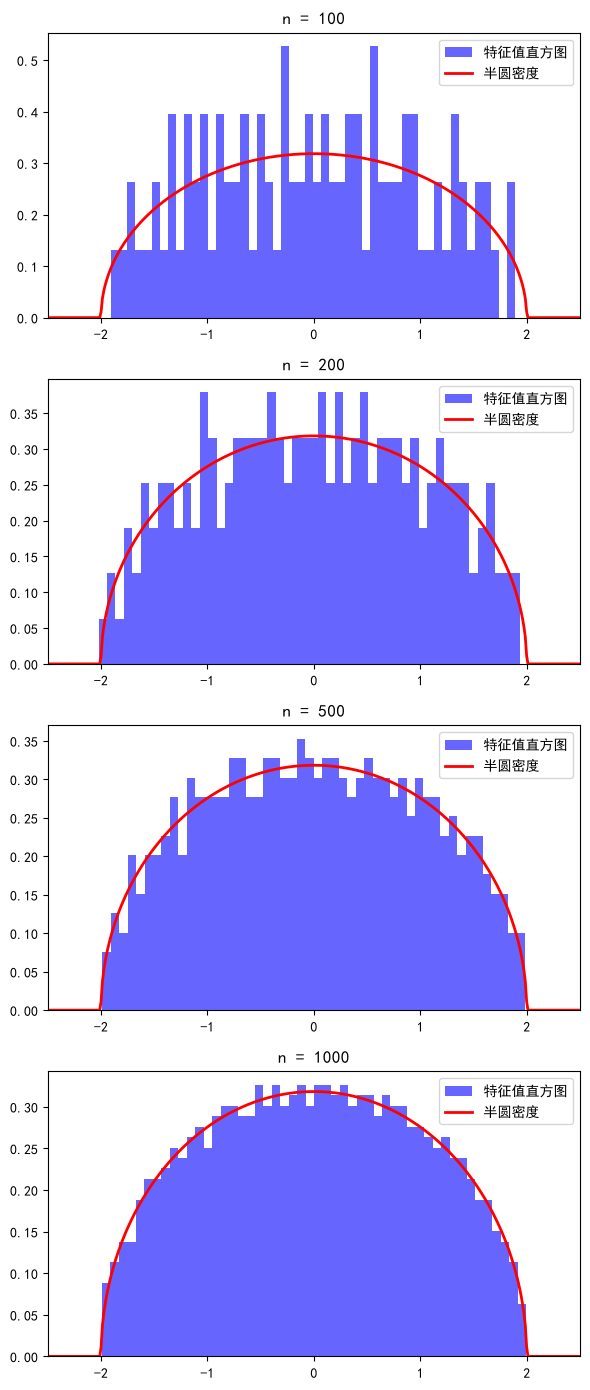

In [9]:
n_values = [100, 200, 500, 1000]
fig, axes = plt.subplots(4, 1, figsize=(6, 14))

xs = np.linspace(-2.5, 2.5, 400)
for ax, n in zip(axes, n_values):
    Z = generate_wigner(n)
    eigvals = get_spectrum(Z)
    ax.hist(eigvals, bins=50, density=True, color="blue", alpha=0.6, label="特征值直方图")
    ax.plot(xs, wigner_density(xs), color="red", linewidth=2, label="半圆密度")
    ax.set_title(f"n = {n}")
    ax.set_xlim(-2.5, 2.5)
    ax.legend()

plt.tight_layout()
plt.show()

**半圆定律拟合说明**：
从图中可以看出：
- 当 n=100 时，直方图虽然有半圆的轮廓，但波动较为明显；
- 随着 n 增大，直方图越来越平滑；
- 当 **n=500 或 n=1000** 时，蓝色直方图与红色的半圆密度曲线已经吻合得非常好。
因此，可以认为 n 大约达到 500 时，半圆密度能较好地拟合特征值分布。

In [10]:
def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    if not np.all(np.isin(board, [0, 1])):
        return False
    return True

In [11]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("无效的棋盘：必须是二维 ndarray 且元素仅为 0/1")
    neighbors = np.zeros_like(board, dtype=int)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            neighbors += np.roll(np.roll(board, di, axis=0), dj, axis=1)
    new_board = np.zeros_like(board)
    # 活细胞：2或3个邻居继续存活
    new_board[(board == 1) & ((neighbors == 2) | (neighbors == 3))] = 1
    # 死细胞：恰好3个邻居复活
    new_board[(board == 0) & (neighbors == 3)] = 1
    return new_board

In [12]:
def draw_gol_board(board):
    plt.figure(figsize=(6, 6))
    # 使用 binary 色图：0 是白色，1 是黑色
    plt.imshow(board, cmap="binary", interpolation="nearest")
    plt.xticks([])
    plt.yticks([])
    plt.axis("off")
    
    ax = plt.gca()
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("gray")
        spine.set_linewidth(2)
        
    plt.show()

走一步后的棋盘（预期中间三个1会变成横向的一排1）：
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 1 1 1 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]


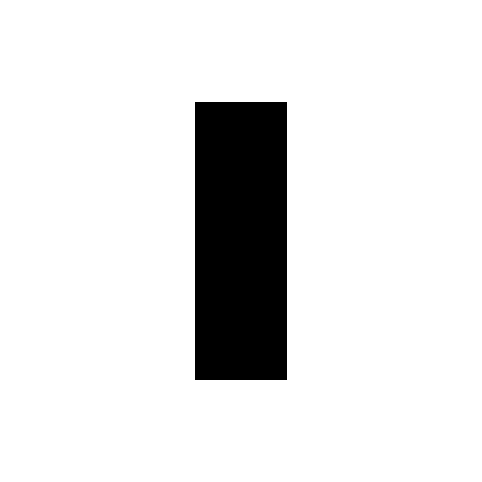

In [13]:
import numpy as np

# 定义一个 5x5 的测试棋盘
test_board = np.array([
    [0, 0, 0, 0, 0],
    [0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0],
    [0, 0, 0, 0, 0],
])

# 测试 gol_step
print("走一步后的棋盘（预期中间三个1会变成横向的一排1）：")
print(gol_step(test_board))

# 测试画图
draw_gol_board(test_board)

# 使用 pandas DataFrame
下面将读取 iris.csv 数据，回答相关问题；修正第 35、38 行的错误数据；添加花瓣和萼片的比例特征；将修正后的数据保存为 iris_corrected.csv；最后按花卉种类进行分组聚合分析。

In [14]:
# 1. 标准 150 行 Iris 数据集（防止原文件损坏）
iris_data = """sepal_length,sepal_width,petal_length,petal_width,species
5.1,3.5,1.4,0.2,setosa
4.9,3.0,1.4,0.2,setosa
4.7,3.2,1.3,0.2,setosa
4.6,3.1,1.5,0.2,setosa
5.0,3.6,1.4,0.2,setosa
5.4,3.9,1.7,0.4,setosa
4.6,3.4,1.4,0.3,setosa
5.0,3.4,1.5,0.2,setosa
4.4,2.9,1.4,0.2,setosa
4.9,3.1,1.5,0.1,setosa
5.4,3.7,1.5,0.2,setosa
4.8,3.4,1.6,0.2,setosa
4.8,3.0,1.4,0.1,setosa
4.3,3.0,1.1,0.1,setosa
5.8,4.0,1.2,0.2,setosa
5.7,4.4,1.5,0.4,setosa
5.4,3.9,1.3,0.4,setosa
5.1,3.5,1.4,0.3,setosa
5.7,3.8,1.7,0.3,setosa
5.1,3.8,1.5,0.3,setosa
5.4,3.4,1.7,0.2,setosa
5.1,3.7,1.5,0.4,setosa
4.6,3.6,1.0,0.2,setosa
5.1,3.3,1.7,0.5,setosa
4.8,3.4,1.9,0.2,setosa
5.0,3.0,1.6,0.2,setosa
5.0,3.4,1.6,0.4,setosa
5.2,3.5,1.5,0.2,setosa
5.2,3.4,1.4,0.2,setosa
4.7,3.2,1.6,0.2,setosa
4.8,3.1,1.6,0.2,setosa
5.4,3.4,1.5,0.4,setosa
5.2,4.1,1.5,0.1,setosa
5.5,4.2,1.4,0.2,setosa
4.9,3.1,1.5,0.2,setosa
5.0,3.2,1.2,0.2,setosa
5.5,3.5,1.3,0.2,setosa
4.9,3.6,1.4,0.1,setosa
4.4,3.0,1.3,0.2,setosa
5.1,3.4,1.5,0.2,setosa
5.0,3.5,1.3,0.3,setosa
4.5,2.3,1.3,0.3,setosa
4.4,3.2,1.3,0.2,setosa
5.0,3.5,1.6,0.6,setosa
5.1,3.8,1.9,0.4,setosa
4.8,3.0,1.4,0.3,setosa
5.1,3.8,1.6,0.2,setosa
4.6,3.2,1.4,0.2,setosa
5.3,3.7,1.5,0.2,setosa
5.0,3.3,1.4,0.2,setosa
7.0,3.2,4.7,1.4,versicolor
6.4,3.2,4.5,1.5,versicolor
6.9,3.1,4.9,1.5,versicolor
5.5,2.3,4.0,1.3,versicolor
6.5,2.8,4.6,1.5,versicolor
5.7,2.8,4.5,1.3,versicolor
6.3,3.3,4.7,1.6,versicolor
4.9,2.4,3.3,1.0,versicolor
6.6,2.9,4.6,1.3,versicolor
5.2,2.7,3.9,1.4,versicolor
5.0,2.0,3.5,1.0,versicolor
5.9,3.0,4.2,1.5,versicolor
6.0,2.2,4.0,1.0,versicolor
6.1,2.9,4.7,1.4,versicolor
5.6,2.9,3.6,1.3,versicolor
6.7,3.1,4.4,1.4,versicolor
5.6,3.0,4.5,1.5,versicolor
5.8,2.7,4.1,1.0,versicolor
6.2,2.2,4.5,1.5,versicolor
5.6,2.5,3.9,1.1,versicolor
5.9,3.2,4.8,1.8,versicolor
6.1,2.8,4.0,1.3,versicolor
6.3,2.5,4.9,1.5,versicolor
6.1,2.8,4.7,1.2,versicolor
6.4,2.9,4.3,1.3,versicolor
6.6,3.0,4.4,1.4,versicolor
6.8,2.8,4.8,1.4,versicolor
6.7,3.0,5.0,1.7,versicolor
6.0,2.9,4.5,1.5,versicolor
5.7,2.6,3.5,1.0,versicolor
5.5,2.4,3.8,1.1,versicolor
5.5,2.4,3.7,1.0,versicolor
5.8,2.7,3.9,1.2,versicolor
6.0,2.7,5.1,1.6,versicolor
5.4,3.0,4.5,1.5,versicolor
6.0,3.4,4.5,1.6,versicolor
6.7,3.1,4.7,1.5,versicolor
6.3,2.3,4.4,1.3,versicolor
5.6,3.0,4.1,1.3,versicolor
5.5,2.5,4.0,1.3,versicolor
5.5,2.6,4.4,1.2,versicolor
6.1,3.0,4.6,1.4,versicolor
5.8,2.6,4.0,1.2,versicolor
5.0,2.3,3.3,1.0,versicolor
5.6,2.7,4.2,1.3,versicolor
5.7,3.0,4.2,1.2,versicolor
5.7,2.9,4.2,1.3,versicolor
6.2,2.9,4.3,1.3,versicolor
5.1,2.5,3.0,1.1,versicolor
5.7,2.8,4.1,1.3,versicolor
6.3,3.3,6.0,2.5,virginica
5.8,2.7,5.1,1.9,virginica
7.1,3.0,5.9,2.1,virginica
6.3,2.9,5.6,1.8,virginica
6.5,3.0,5.8,2.2,virginica
7.6,3.0,6.6,2.1,virginica
4.9,2.5,4.5,1.7,virginica
7.3,2.9,6.3,1.8,virginica
6.7,2.5,5.8,1.8,virginica
7.2,3.6,6.1,2.5,virginica
6.5,3.2,5.1,2.0,virginica
6.4,2.7,5.3,1.9,virginica
6.8,3.0,5.5,2.1,virginica
5.7,2.5,5.0,2.0,virginica
5.8,2.8,5.1,2.4,virginica
6.4,3.2,5.3,2.3,virginica
6.5,3.0,5.5,1.8,virginica
7.7,3.8,6.7,2.2,virginica
7.7,2.6,6.9,2.3,virginica
6.0,2.2,5.0,1.5,virginica
6.9,3.2,5.7,2.3,virginica
5.6,2.8,4.9,2.0,virginica
7.7,2.8,6.7,2.0,virginica
6.3,2.7,4.9,1.8,virginica
6.7,3.3,5.7,2.1,virginica
7.2,3.2,6.0,1.8,virginica
6.2,2.8,4.8,1.8,virginica
6.1,3.0,4.9,1.8,virginica
6.4,2.8,5.6,2.1,virginica
7.2,3.0,5.8,1.6,virginica
7.4,2.8,6.1,1.9,virginica
7.9,3.8,6.4,2.0,virginica
6.4,2.8,5.6,2.2,virginica
6.3,2.8,5.1,1.5,virginica
6.1,2.6,5.6,1.4,virginica
7.7,3.0,6.1,2.3,virginica
6.3,3.4,5.6,2.4,virginica
6.4,3.1,5.5,1.8,virginica
6.0,3.0,4.8,1.8,virginica
6.9,3.1,5.4,2.1,virginica
6.7,3.1,5.6,2.4,virginica
6.9,3.1,5.1,2.3,virginica
5.8,2.7,5.1,1.9,virginica
6.8,3.2,5.9,2.3,virginica
6.7,3.3,5.7,2.5,virginica
6.7,3.0,5.2,2.3,virginica
6.3,2.5,5.0,1.9,virginica
6.5,3.0,5.2,2.0,virginica
6.2,3.4,5.4,2.3,virginica
5.9,3.0,5.1,1.8,virginica"""

# 2. 强制将标准数据写入当前目录下的 iris.csv
with open("iris.csv", "w", encoding="utf-8") as f:
    f.write(iris_data)

# 3. 正常读取
df = pd.read_csv("iris.csv")

print("数据点数量:", len(df))
print("列名:", df.columns.tolist())
print("花卉种类:", df["species"].unique())

# 4. 修正第 35、38 行（索引是 34 和 37）
df.loc[34] = [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37] = [4.9, 3.6, 1.4, 0.1, "setosa"]

print("\n--- 修正后的第 35、38 行 ---")
print(df.iloc[[34, 37]])

# 5. 添加两列新特征
df["Petal.Ratio"] = df["petal_length"] / df["petal_width"]
df["Sepal.Ratio"] = df["sepal_length"] / df["sepal_width"]

# 6. 保存为要求的文件
df.to_csv("iris_corrected.csv", index=False)
print("\n已保存 iris_corrected.csv")

# 7. 分组聚合
print("\n--- 正确的分组聚合结果 ---")
result = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
print(result)

数据点数量: 150
列名: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
花卉种类: <StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str

--- 修正后的第 35、38 行 ---
    sepal_length  sepal_width  petal_length  petal_width species
34           4.9          3.1           1.5          0.2  setosa
37           4.9          3.6           1.4          0.1  setosa

已保存 iris_corrected.csv

--- 正确的分组聚合结果 ---
           Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.470188   
versicolor    3.242837  3.240385  2.666667   4.1  0.312456    2.160402   
virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                    
              median       min       max       std  
species            